# 1. Fair pairs: why you cannot blink SPHEREx

Each pixel of a SPHEREx exposure sees its own color through a linear variable filter. This notebook shows how much a steady star seems to change when two exposures see different colors, and how CHRONOS picks fair pairs.

In [1]:
import os, sys, json, math, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "backend"))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
for f in os.listdir(os.path.join(ROOT, "scripts", "fonts")):
    font_manager.fontManager.addfont(os.path.join(ROOT, "scripts", "fonts", f))
plt.rcParams.update({"font.family": "EB Garamond", "font.size": 12, "figure.facecolor": "#f5f0e6", "axes.facecolor": "#fbf8f2"})
import core, sky, pipeline as P

## A practice field

Six arrays, two colors per array in each visit, four visits half a year apart. Surveys 3 and 4 sit half a channel away.

In [2]:
spec = sky.make_spec(3)
E, truth, cat = sky.render(spec)
print(len(E), "exposures;", sorted({e.det for e in E}), "arrays")
for e in E[:4]:
    print(e.id, "array", e.det, "lambda %.4f micron" % e.lam, "width %.4f" % e.bw, "frame", e.frame)

48 exposures; [1, 2, 3, 4, 5, 6] arrays
f3_e0_d1_s0 array 1 lambda 0.8084 micron width 0.0207 frame f0_1_0
f3_e0_d1_s1 array 1 lambda 1.0093 micron width 0.0259 frame f0_1_1
f3_e0_d2_s0 array 2 lambda 1.1903 micron width 0.0290 frame f0_2_0
f3_e0_d2_s1 array 2 lambda 1.4974 micron width 0.0365 frame f0_2_1


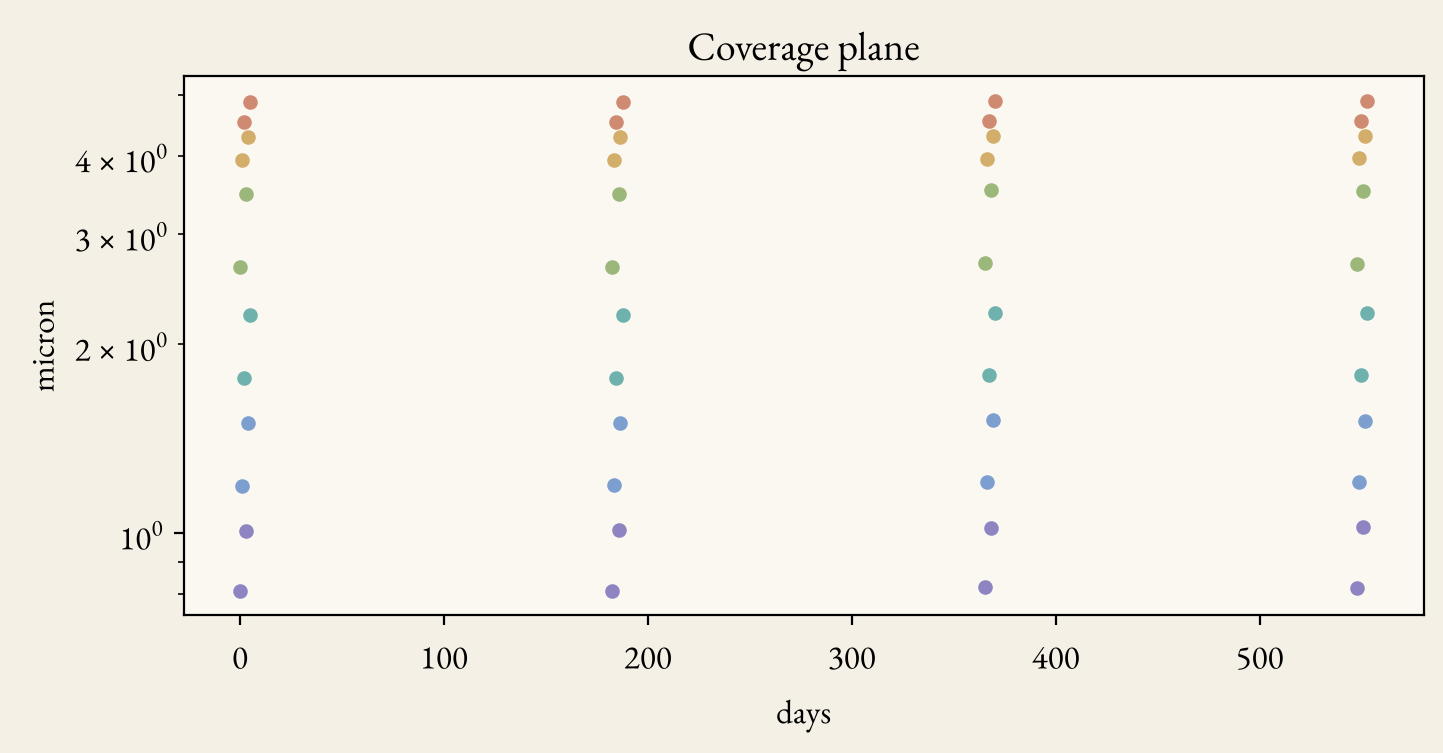

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
col = {1: "#8f84c2", 2: "#7d9fd0", 3: "#6fb1ad", 4: "#9cb77a", 5: "#d3ad6a", 6: "#cf8a72"}
t0 = min(e.mjd for e in E)
for e in E:
    ax.scatter(e.mjd - t0, e.lam, color=col[e.det], s=18)
ax.set_yscale("log"); ax.set_xlabel("days"); ax.set_ylabel("micron"); ax.set_title("Coverage plane")
plt.show()

## How far apart are the colors?

Color offset in channel widths for the same array and step, visit 1 against visits 2, 3 and 4.

In [4]:
a = [e for e in E if e.det == 3 and e.id.endswith("s0")]
for b in a[1:]:
    print(a[0].id, "->", b.id, "offset %.2f channel" % (abs(a[0].lam - b.lam) / b.bw), "fair" if P.color_distance(a[0], b) <= 0.5 else "NOT fair")

f3_e0_d3_s0 -> f3_e1_d3_s0 offset 0.00 channel fair
f3_e0_d3_s0 -> f3_e2_d3_s0 offset 0.45 channel fair
f3_e0_d3_s0 -> f3_e3_d3_s0 offset 0.48 channel fair


## False change from color alone

A steady star with a spectral slope seems to change brightness between two colors. The false change meter of CHRONOS predicts this change; the fair pair rule avoids it.

In [5]:
for slope in (-0.6, 0.0, 0.6, 1.2):
    s = dict(mag=15.0, slope=slope)
    f1 = sky.flux_of(dict(s), a[0].lam, a[0].mjd, 0)
    f3 = sky.flux_of(dict(s), a[2].lam, a[2].mjd, 2)
    print(f"slope {slope:+.1f} mag per micron: apparent change {100 * (f3 / f1 - 1):+.2f} percent with no change in the sky")

slope -0.6 mag per micron: apparent change -1.07 percent with no change in the sky
slope +0.0 mag per micron: apparent change +0.00 percent with no change in the sky
slope +0.6 mag per micron: apparent change +1.08 percent with no change in the sky
slope +1.2 mag per micron: apparent change +2.18 percent with no change in the sky


## Fair co add pairs of a whole field

In [6]:
core.prepare(E)
ref, n, center = P.ref_wcs(E, spec["center"])
S = P.build(E, ref, n, cat)
pairs = P.fair_coadd_pairs(S)
print(sum(p["fair"] and p["release_same"] for p in pairs), "fair of", len(pairs), "visit pairs on the same array")
for p in pairs[:8]:
    print("visit", p["q1"] + 1, "and", p["q2"] + 1, "array", p["det"], "color %.2f" % p["color"], "fair" if p["fair"] else "", "" if p["release_same"] else "release differs")

11 fair of 36 visit pairs on the same array
visit 1 and 2 array 1 color 0.04 fair 
visit 1 and 2 array 2 color 0.03 fair 
visit 1 and 2 array 3 color 0.03 fair 
visit 1 and 2 array 4 color 0.02 fair release differs
visit 1 and 2 array 5 color 0.09 fair 
visit 1 and 2 array 6 color 0.01 fair 
visit 1 and 3 array 1 color 0.50  
visit 1 and 3 array 2 color 0.52  
